# Wine Classification — Machine Learning Midterm

**Reproducible notebook:** Sections 1–10 for Wine, Section 11 cross-dataset analysis, Section 12 CSV export and inventory. Run cells from top to bottom using the project `.venv`. This notebook does not overwrite Breast Cancer results until the final merge step; backups are created before export. 

> Each section requires your own brief interpretation in your own words for submission. This notebook contains technical diagnostics, not a finished report.

## 1. Loading the Dataset

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display as notebook_display
from sklearn.datasets import load_wine

SEEDS = [42, 52, 62]
LABELS = [0, 1, 2]
DATASET = "Wine"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

wine = load_wine()
X = wine.data
y = wine.target
X_df = pd.DataFrame(X, columns=wine.feature_names)
y_series = pd.Series(y, index=X_df.index, name="target")
df = X_df.copy()
df["target"] = y_series

print("\nX shape:", X_df.shape)
print("y shape:", y_series.shape)
print("\nFirst five rows (features + target):")
notebook_display(df.head())
print("Feature names:", list(X_df.columns))
print("Target labels:", LABELS)
print("Target names:", list(wine.target_names))
print("Class mapping:", dict(zip(LABELS, wine.target_names)))
print("Class counts:")
notebook_display(y_series.value_counts().sort_index().rename("count").to_frame())

Working directory: c:\Users\PC\Desktop\Machine_Learning_Project
Python: 3.13.2
scikit-learn: 1.9.1
pandas: 3.1.1
numpy: 2.5.4

X shape: (178, 13)
y shape: (178,)

First five rows (features + target):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target labels: [0, 1, 2]
Target names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Class mapping: {0: np.str_('class_0'), 1: np.str_('class_1'), 2: np.str_('class_2')}
Class counts:


,count
target,
0,59
1,71
2,48


## 2. Dataset Quality Checks

Check missing values, duplicates, feature dtypes, and **potential** outliers. Do not remove outliers or impute the complete dataset.

In [2]:
missing_counts = df.isna().sum()
duplicate_rows = int(df.duplicated().sum())
feature_dtypes = X_df.dtypes
numeric_features = list(X_df.select_dtypes(include="number").columns)
categorical_features = [c for c in X_df.columns if c not in numeric_features]

print("Missing values per column:")
notebook_display(missing_counts.rename("missing_count").to_frame())
print("Total missing values:", int(missing_counts.sum()))
print("Duplicate rows:", duplicate_rows)
print("Feature types:")
notebook_display(feature_dtypes.rename("dtype").to_frame())
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

q1 = X_df.quantile(0.25)
q3 = X_df.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_counts = ((X_df.lt(lower_bound)) | (X_df.gt(upper_bound))).sum()
outlier_table = pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "lower_bound": lower_bound, "upper_bound": upper_bound,
    "potential_outliers": outlier_counts
}).sort_values("potential_outliers", ascending=False)
print("Potential IQR outliers (not deleted):")
notebook_display(outlier_table)

assert not y_series.isna().any(), "Target labels contain missing values"
assert int(X_df.isna().sum().sum()) == 0, "Wine has unexpected missing values; add train-only imputation before continuing"

Missing values per column:


,missing_count
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Total missing values: 0
Duplicate rows: 0
Feature types:


,dtype
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


Numerical features: 13
Categorical features: 0
Potential IQR outliers (not deleted):


,Q1,Q3,IQR,lower_bound,upper_bound,potential_outliers
magnesium,88.0000,107.0000,19.0000,59.50000,135.50000,4
alcalinity_of_ash,17.2000,21.5000,4.3000,10.75000,27.95000,4
color_intensity,3.2200,6.2000,2.9800,-1.25000,10.67000,4
malic_acid,1.6025,3.0825,1.4800,-0.61750,5.30250,3
ash,2.2100,2.5575,0.3475,1.68875,3.07875,3
proanthocyanins,1.2500,1.9500,0.7000,0.20000,3.00000,2
hue,0.7825,1.1200,0.3375,0.27625,1.62625,1
alcohol,12.3625,13.6775,1.3150,10.39000,15.65000,0
total_phenols,1.7425,2.8000,1.0575,0.15625,4.38625,0
nonflavanoid_phenols,0.2700,0.4375,0.1675,0.01875,0.68875,0


## 3. Exploratory Data Analysis (EDA)

Full-dataset statistics here are **descriptive only**; they are not used to fit preprocessing or choose modeling features.

Descriptive statistics (all 13 features):


,mean,median,min,max,std,Q1,Q3
alcohol,13.000618,13.050,11.03,14.83,0.811827,12.3625,13.6775
malic_acid,2.336348,1.865,0.74,5.80,1.117146,1.6025,3.0825
ash,2.366517,2.360,1.36,3.23,0.274344,2.2100,2.5575
alcalinity_of_ash,19.494944,19.500,10.60,30.00,3.339564,17.2000,21.5000
magnesium,99.741573,98.000,70.00,162.00,14.282484,88.0000,107.0000
total_phenols,2.295112,2.355,0.98,3.88,0.625851,1.7425,2.8000
flavanoids,2.029270,2.135,0.34,5.08,0.998859,1.2050,2.8750
nonflavanoid_phenols,0.361854,0.340,0.13,0.66,0.124453,0.2700,0.4375
proanthocyanins,1.590899,1.555,0.41,3.58,0.572359,1.2500,1.9500
color_intensity,5.058090,4.690,1.28,13.00,2.318286,3.2200,6.2000


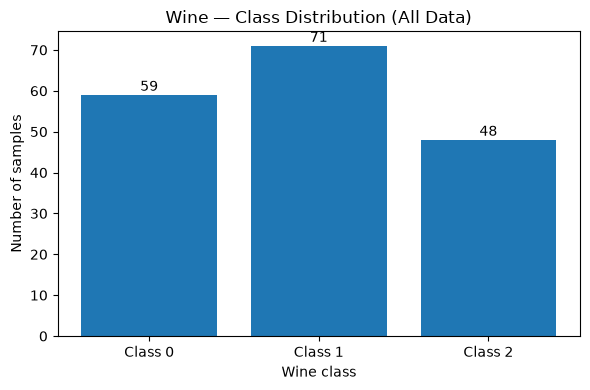

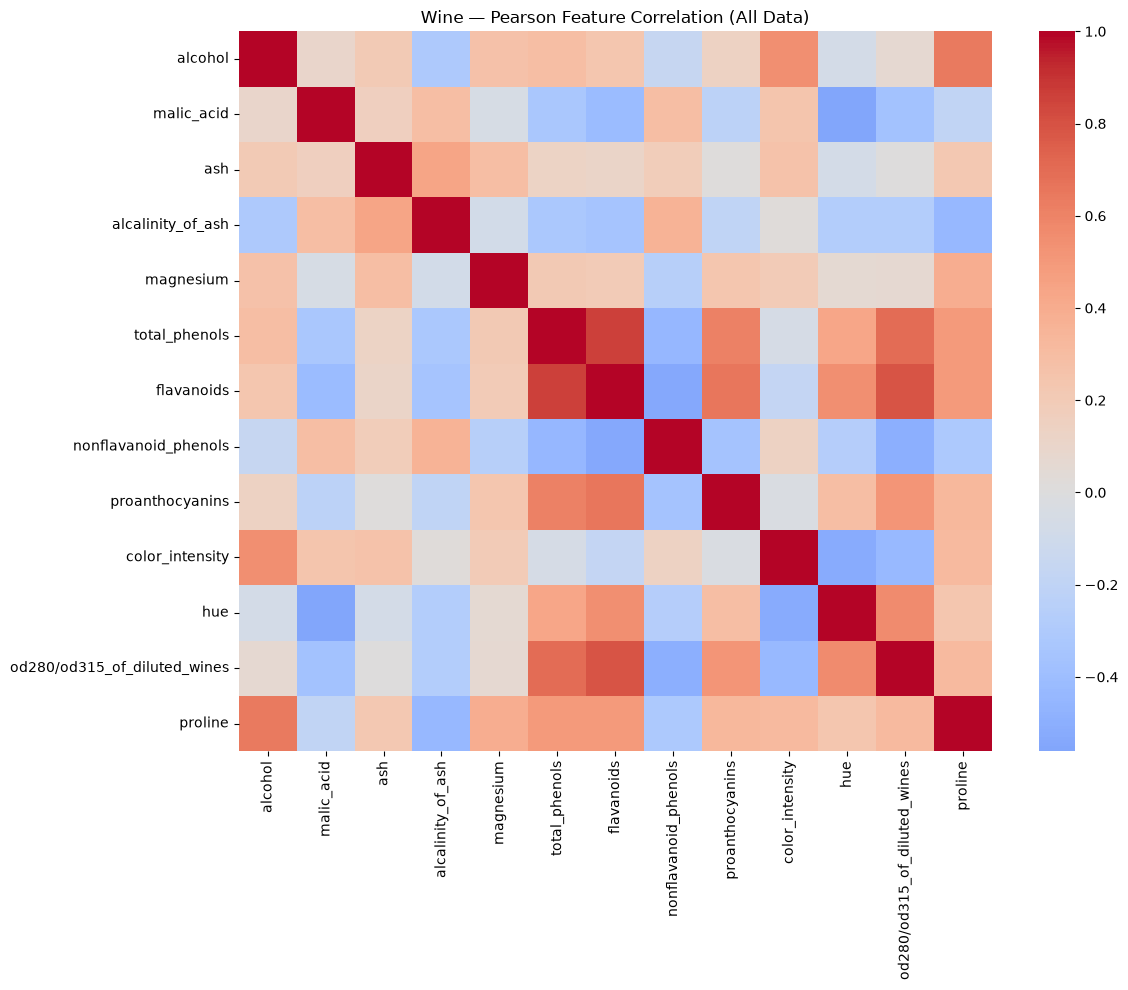

Three strongest unique feature pairs by absolute Pearson correlation:


,,correlation
total_phenols,flavanoids,0.864564
flavanoids,od280/od315_of_diluted_wines,0.787194
total_phenols,od280/od315_of_diluted_wines,0.699949


In [3]:
wine_descriptive = pd.DataFrame({
    "mean": X_df.mean(),
    "median": X_df.median(),
    "min": X_df.min(),
    "max": X_df.max(),
    "std": X_df.std(),
    "Q1": X_df.quantile(0.25),
    "Q3": X_df.quantile(0.75),
})
print("Descriptive statistics (all 13 features):")
notebook_display(wine_descriptive)

counts = y_series.value_counts().reindex(LABELS)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([f"Class {i}" for i in LABELS], counts.values)
for i, count in enumerate(counts.values):
    ax.text(i, count + 1, str(count), ha="center")
ax.set(xlabel="Wine class", ylabel="Number of samples", title="Wine — Class Distribution (All Data)")
fig.tight_layout()
fig.savefig(FIG_DIR / "wine_class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

correlation_matrix = X_df.corr(method="pearson")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Wine — Pearson Feature Correlation (All Data)")
fig.tight_layout()
fig.savefig(FIG_DIR / "wine_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1))
pairs = upper.stack().rename("correlation")
top3 = pairs.loc[pairs.abs().sort_values(ascending=False).index].head(3)
print("Three strongest unique feature pairs by absolute Pearson correlation:")
notebook_display(top3.to_frame())

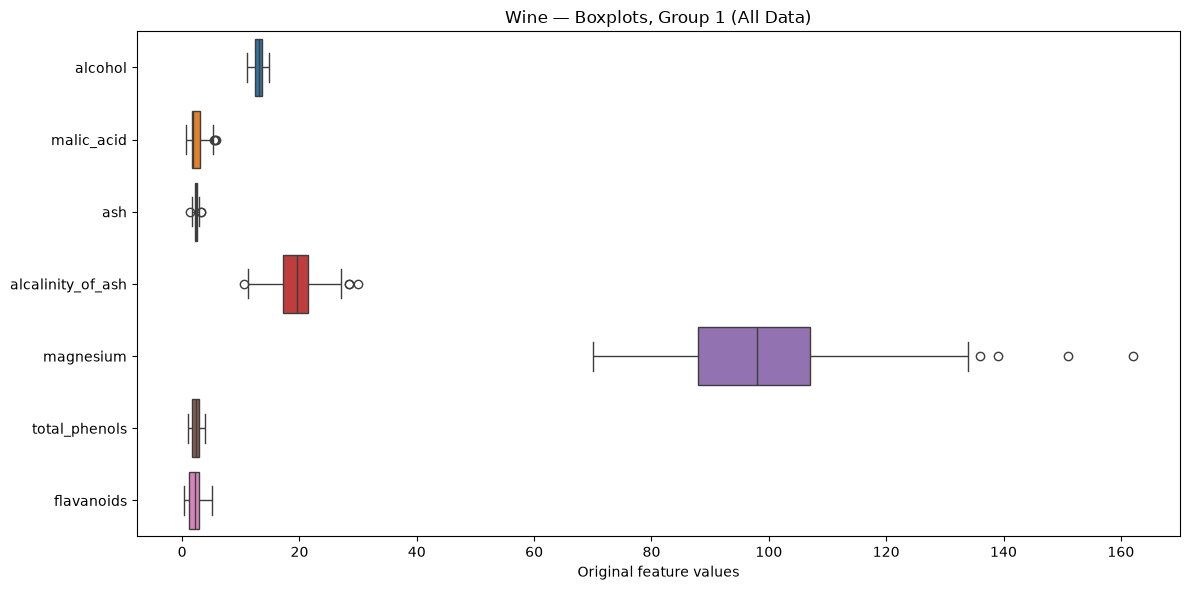

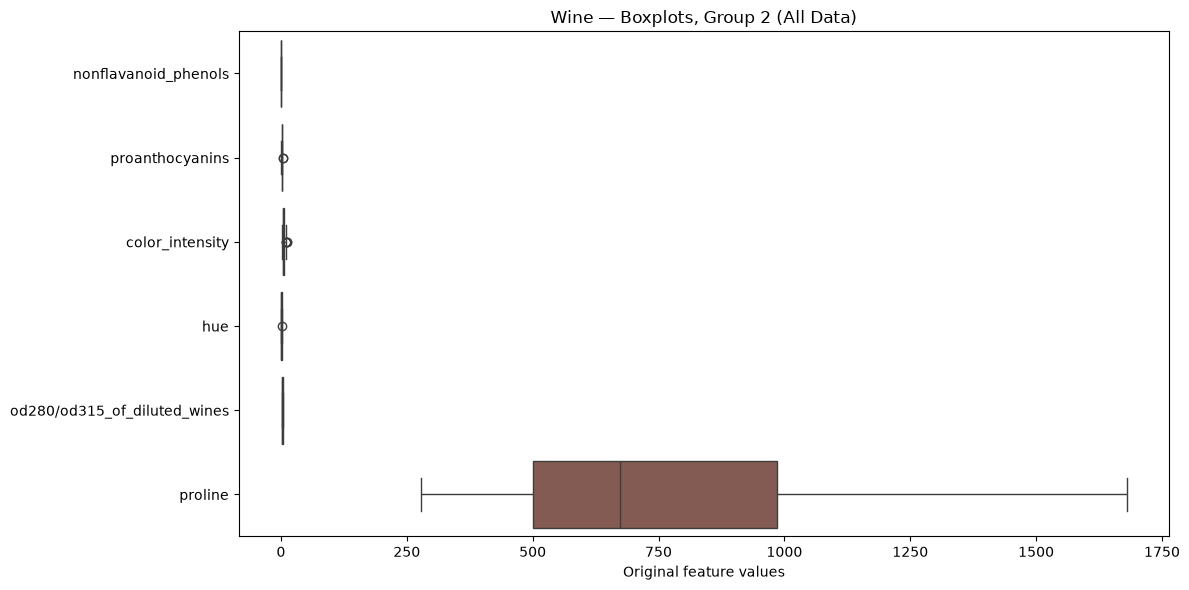

Explain at least two observed feature-range or outlier differences in your own text.


In [4]:
feature_groups = [list(X_df.columns[:7]), list(X_df.columns[7:])]
for group_num, features in enumerate(feature_groups, start=1):
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.boxplot(data=X_df[features], orient="h", ax=ax)
    ax.set(title=f"Wine — Boxplots, Group {group_num} (All Data)", xlabel="Original feature values")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"wine_boxplots_group{group_num}.png", dpi=200, bbox_inches="tight")
    plt.show()
print("Explain at least two observed feature-range or outlier differences in your own text.")

## 4. Splitting the Dataset

Reserve the **same fixed 20% test set** first, then repeat the training/validation split using seeds 42, 52 and 62. Approximate overall ratios are 70% / 10% / 20%.

In [5]:
from sklearn.model_selection import train_test_split

train_val_idx, test_idx = train_test_split(
    X_df.index, test_size=0.20, stratify=y_series, random_state=42
)
test_idx = pd.Index(test_idx)
X_test = X_df.loc[test_idx].copy()
y_test = y_series.loc[test_idx].copy()

splits = {}
split_rows = []
for seed in SEEDS:
    train_idx, val_idx = train_test_split(
        train_val_idx,
        test_size=0.125,
        stratify=y_series.loc[train_val_idx],
        random_state=seed,
    )
    train_idx, val_idx = pd.Index(train_idx), pd.Index(val_idx)
    splits[seed] = {
        "train_idx": train_idx,
        "val_idx": val_idx,
        "test_idx": test_idx,
        "X_train": X_df.loc[train_idx].copy(),
        "X_val": X_df.loc[val_idx].copy(),
        "y_train": y_series.loc[train_idx].copy(),
        "y_val": y_series.loc[val_idx].copy(),
    }
    train_set, val_set, test_set = map(set, [train_idx, val_idx, test_idx])
    assert not (train_set & val_set or train_set & test_set or val_set & test_set)
    assert len(train_set | val_set | test_set) == len(X_df)
    assert splits[seed]["test_idx"].equals(test_idx)

    for name, idx in [("Train", train_idx), ("Validation", val_idx), ("Test", test_idx)]:
        count = y_series.loc[idx].value_counts().reindex(LABELS, fill_value=0)
        split_rows.append({
            "seed": seed, "subset": name, "count": len(idx),
            "percent_of_full": 100 * len(idx) / len(X_df),
            **{f"class_{c}_count": int(count.loc[c]) for c in LABELS},
        })

wine_split_summary = pd.DataFrame(split_rows)
notebook_display(wine_split_summary)
print("Fixed test indices (inspectable):", test_idx.tolist())
for seed in SEEDS:
    print(f"Seed {seed}: train indices =", splits[seed]["train_idx"].tolist())
    print(f"Seed {seed}: validation indices =", splits[seed]["val_idx"].tolist())

,seed,subset,count,percent_of_full,class_0_count,class_1_count,class_2_count
0,42,Train,124,69.662921,41,50,33
1,42,Validation,18,10.112360,6,7,5
2,42,Test,36,20.224719,12,14,10
3,52,Train,124,69.662921,41,50,33
4,52,Validation,18,10.112360,6,7,5
5,52,Test,36,20.224719,12,14,10
6,62,Train,124,69.662921,41,50,33
7,62,Validation,18,10.112360,6,7,5
8,62,Test,36,20.224719,12,14,10


Fixed test indices (inspectable): [10, 134, 28, 121, 62, 51, 7, 66, 129, 166, 102, 143, 42, 130, 14, 108, 105, 20, 100, 38, 93, 60, 22, 18, 98, 64, 58, 132, 112, 155, 48, 176, 94, 177, 164, 173]
Seed 42: train indices = [163, 148, 116, 122, 115, 147, 46, 141, 57, 168, 36, 159, 103, 29, 23, 68, 101, 50, 11, 113, 114, 34, 27, 125, 165, 49, 74, 83, 162, 31, 30, 25, 44, 149, 26, 9, 63, 13, 77, 24, 142, 85, 144, 109, 41, 71, 78, 16, 92, 47, 90, 96, 150, 69, 133, 138, 91, 124, 15, 126, 139, 140, 95, 82, 56, 40, 12, 161, 99, 61, 136, 170, 156, 3, 154, 104, 37, 111, 53, 135, 76, 106, 32, 118, 119, 43, 21, 80, 65, 72, 153, 17, 67, 128, 146, 175, 55, 84, 73, 117, 70, 127, 8, 88, 87, 59, 54, 39, 45, 2, 81, 19, 174, 171, 52, 137, 167, 5, 151, 107, 131, 152, 172, 75]
Seed 42: validation indices = [157, 145, 158, 110, 6, 120, 0, 89, 123, 33, 79, 35, 1, 97, 4, 86, 169, 160]
Seed 52: train indices = [128, 135, 53, 27, 172, 141, 169, 11, 131, 79, 111, 83, 75, 115, 86, 84, 12, 87, 4, 89, 147, 126, 0, 55

## 5. Data Preprocessing and Scaling

No imputation is performed when no values are missing. Use StandardScaler fitted separately on each **training** split. Only seed 42's scaler transforms final test features.

In [6]:
from sklearn.preprocessing import StandardScaler

scalers = {}
scaled_data = {}
for seed in SEEDS:
    train_data = splits[seed]["X_train"]
    val_data = splits[seed]["X_val"]
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train_data)
    val_scaled = scaler.transform(val_data)
    scalers[seed] = scaler
    scaled_data[seed] = {
        "X_train_scaled": pd.DataFrame(train_scaled, index=train_data.index, columns=X_df.columns),
        "X_val_scaled": pd.DataFrame(val_scaled, index=val_data.index, columns=X_df.columns),
    }
    if seed == 42:
        scaled_data[seed]["X_test_scaled"] = pd.DataFrame(
            scaler.transform(X_test), index=X_test.index, columns=X_df.columns
        )
    print(f"Seed {seed}: train {train_scaled.shape}, validation {val_scaled.shape}")

print("Seed 42 — first five ORIGINAL training rows:")
notebook_display(splits[42]["X_train"].head())
print("Seed 42 — same five SCALED training rows:")
notebook_display(scaled_data[42]["X_train_scaled"].head())
print("Maximum absolute train-scaled feature mean:",
      scaled_data[42]["X_train_scaled"].mean().abs().max())
print("Scaled train std range (ddof=0):",
      scaled_data[42]["X_train_scaled"].std(ddof=0).min(),
      scaled_data[42]["X_train_scaled"].std(ddof=0).max())

Seed 42: train (124, 13), validation (18, 13)
Seed 52: train (124, 13), validation (18, 13)
Seed 62: train (124, 13), validation (18, 13)
Seed 42 — first five ORIGINAL training rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


Seed 42 — same five SCALED training rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


Maximum absolute train-scaled feature mean: 3.233972229795214e-15
Scaled train std range (ddof=0): 0.9999999999999999 1.0


## 6. Preparing the Two Data Representations

All 13 original features are retained. Only scaling changes; within one seed the training and validation indices are identical for every model.

In [7]:
def training_validation_features(seed, representation):
    if representation == "unscaled":
        return splits[seed]["X_train"], splits[seed]["X_val"]
    if representation == "scaled":
        return scaled_data[seed]["X_train_scaled"], scaled_data[seed]["X_val_scaled"]
    raise ValueError("Representation must be 'unscaled' or 'scaled'")

def fixed_test_features(representation):
    if representation == "unscaled":
        return X_test
    if representation == "scaled":
        return scaled_data[42]["X_test_scaled"]
    raise ValueError("Invalid representation")

for representation in ["unscaled", "scaled"]:
    tr, va = training_validation_features(42, representation)
    print(representation, "Train:", tr.shape, "Validation:", va.shape)
assert splits[42]["X_train"].shape[1] == 13

unscaled Train: (124, 13) Validation: (18, 13)
scaled Train: (124, 13) Validation: (18, 13)


## 7. Training the Classification Models

Grid per dataset: five Decision Trees, five KNN settings and one default GaussianNB × two representations × three seeds = **66 fitted classifiers**. Every run records train accuracy/F1, validation metrics, and an experiment ID.

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

specs = []
for depth in [2, 3, 5, 10, None]:
    specs.append({"algorithm": "DecisionTree", "model": f"DecisionTree_depth_{depth}",
                  "parameter": f"max_depth={depth}", "slug": f"dt_depth_{depth}"})
for k in [1, 3, 5, 7, 11]:
    specs.append({"algorithm": "KNN", "model": f"KNN_k_{k}",
                  "parameter": f"n_neighbors={k}; weights=uniform; metric=euclidean",
                  "slug": f"knn_k_{k}"})
specs.append({"algorithm": "GaussianNB", "model": "GaussianNB",
              "parameter": "defaults", "slug": "gaussiannb_default"})

def make_classifier(spec, seed):
    if spec["algorithm"] == "DecisionTree":
        depth = spec["parameter"].split("=")[1]
        return DecisionTreeClassifier(max_depth=None if depth == "None" else int(depth),
                                      random_state=seed)
    if spec["algorithm"] == "KNN":
        k = int(spec["parameter"].split(";")[0].split("=")[1])
        return KNeighborsClassifier(n_neighbors=k, weights="uniform", metric="euclidean")
    return GaussianNB()

def undefined_metric_classes(y_true, y_pred):
    true_count = pd.Series(y_true).value_counts()
    pred_count = pd.Series(y_pred).value_counts()
    undefined_precision = [str(c) for c in LABELS if pred_count.get(c, 0) == 0]
    undefined_recall = [str(c) for c in LABELS if true_count.get(c, 0) == 0]
    return ",".join(undefined_precision), ",".join(undefined_recall)

wine_run_records = []
wine_seed42_models = {}
for seed in SEEDS:
    train_labels = splits[seed]["y_train"]
    val_labels = splits[seed]["y_val"]
    for representation in ["unscaled", "scaled"]:
        X_tr, X_val = training_validation_features(seed, representation)
        for spec in specs:
            model = make_classifier(spec, seed)
            model.fit(X_tr, train_labels)
            train_pred = model.predict(X_tr)
            val_pred = model.predict(X_val)
            assert list(model.classes_) == LABELS, "Unexpected probability column order"
            val_proba = model.predict_proba(X_val)
            undefined_p, undefined_r = undefined_metric_classes(val_labels, val_pred)
            config_id = f"wine_{spec['slug']}_{representation}"
            record = {
                "dataset": DATASET,
                "run_id": f"{config_id}_s{seed}",
                "config_id": config_id,
                "seed": seed,
                "representation": representation,
                "algorithm": spec["algorithm"],
                "model": spec["model"],
                "parameter": spec["parameter"],
                "train_accuracy": accuracy_score(train_labels, train_pred),
                "train_macro_f1": f1_score(train_labels, train_pred, average="macro", zero_division=0),
                "accuracy": accuracy_score(val_labels, val_pred),
                "precision_macro": precision_score(val_labels, val_pred, average="macro", zero_division=0),
                "recall_macro": recall_score(val_labels, val_pred, average="macro", zero_division=0),
                "f1_macro": f1_score(val_labels, val_pred, average="macro", zero_division=0),
                "roc_auc": roc_auc_score(val_labels, val_proba, labels=LABELS,
                                         multi_class="ovr", average="macro"),
                "undefined_precision_classes": undefined_p,
                "undefined_recall_classes": undefined_r,
            }
            wine_run_records.append(record)
            if seed == 42:
                wine_seed42_models[config_id] = model

wine_classifier_runs = pd.DataFrame(wine_run_records)
assert len(wine_classifier_runs) == 66
assert wine_classifier_runs["run_id"].is_unique
print("Classifier fits:", len(wine_classifier_runs))
print("Undefined metric situations (if any):")
notebook_display(wine_classifier_runs.loc[
    (wine_classifier_runs["undefined_precision_classes"] != "") |
    (wine_classifier_runs["undefined_recall_classes"] != ""),
    ["run_id", "undefined_precision_classes", "undefined_recall_classes"]
])
notebook_display(wine_classifier_runs)

Classifier fits: 66
Undefined metric situations (if any):


,run_id,undefined_precision_classes,undefined_recall_classes


,dataset,run_id,config_id,seed,representation,algorithm,model,parameter,train_accuracy,train_macro_f1,accuracy,precision_macro,recall_macro,f1_macro,roc_auc,undefined_precision_classes,undefined_recall_classes
0,Wine,wine_dt_depth_2_unscaled_s42,wine_dt_depth_2_unscaled,42,unscaled,DecisionTree,DecisionTree_depth_2,max_depth=2,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596,,
1,Wine,wine_dt_depth_3_unscaled_s42,wine_dt_depth_3_unscaled,42,unscaled,DecisionTree,DecisionTree_depth_3,max_depth=3,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645,,
2,Wine,wine_dt_depth_5_unscaled_s42,wine_dt_depth_5_unscaled,42,unscaled,DecisionTree,DecisionTree_depth_5,max_depth=5,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,,
3,Wine,wine_dt_depth_10_unscaled_s42,wine_dt_depth_10_unscaled,42,unscaled,DecisionTree,DecisionTree_depth_10,max_depth=10,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,,
4,Wine,wine_dt_depth_None_unscaled_s42,wine_dt_depth_None_unscaled,42,unscaled,DecisionTree,DecisionTree_depth_None,max_depth=None,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,Wine,wine_knn_k_3_scaled_s62,wine_knn_k_3_scaled,62,scaled,KNN,KNN_k_3,n_neighbors=3; weights=uniform; metric=euclidean,0.959677,0.960888,0.888889,0.896825,0.904762,0.888500,1.000000,,
62,Wine,wine_knn_k_5_scaled_s62,wine_knn_k_5_scaled,62,scaled,KNN,KNN_k_5,n_neighbors=5; weights=uniform; metric=euclidean,0.975806,0.975871,0.944444,0.944444,0.952381,0.944056,1.000000,,
63,Wine,wine_knn_k_7_scaled_s62,wine_knn_k_7_scaled,62,scaled,KNN,KNN_k_7,n_neighbors=7; weights=uniform; metric=euclidean,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000,,
64,Wine,wine_knn_k_11_scaled_s62,wine_knn_k_11_scaled,62,scaled,KNN,KNN_k_11,n_neighbors=11; weights=uniform; metric=euclidean,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000,,


## 8. Validation Performance and Model Selection

Select ONE configuration using mean validation macro-F1 over seeds. Tie-breaks: higher mean accuracy, lower F1 standard deviation, alphabetical config ID. **Do not look at test scores when selecting.**

In [9]:
METRIC_COLS = ["train_accuracy", "train_macro_f1", "accuracy", "precision_macro",
               "recall_macro", "f1_macro", "roc_auc"]

def summarize_classifier_runs(runs):
    agg = {}
    for metric in METRIC_COLS:
        agg[f"{metric}_mean"] = (metric, "mean")
        agg[f"{metric}_std"] = (metric, "std")   # pandas uses sample std, ddof=1
    return runs.groupby(
        ["dataset", "config_id", "algorithm", "model", "parameter", "representation"],
        as_index=False
    ).agg(**agg)

def ranked_configurations(summary):
    return summary.sort_values(
        ["f1_macro_mean", "accuracy_mean", "f1_macro_std", "config_id"],
        ascending=[False, False, True, True],
        kind="mergesort"
    ).reset_index(drop=True)

wine_classifier_summary = ranked_configurations(
    summarize_classifier_runs(wine_classifier_runs)
)
assert len(wine_classifier_summary) == 22
best = wine_classifier_summary.iloc[0]
best_config_id = best["config_id"]
print("Best configuration:", best_config_id)
print("Mean validation macro F1:", best["f1_macro_mean"])
print("Validation macro F1 std:", best["f1_macro_std"])
notebook_display(wine_classifier_summary)

Best configuration: wine_knn_k_11_scaled
Mean validation macro F1: 0.9813519813519814
Validation macro F1 std: 0.032299315758860164


,dataset,config_id,algorithm,model,parameter,representation,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,roc_auc_mean,roc_auc_std
0,Wine,wine_knn_k_11_scaled,KNN,KNN_k_11,n_neighbors=11; weights=uniform; metric=euclidean,scaled,0.965054,0.004656,0.965589,0.004817,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
1,Wine,wine_knn_k_5_scaled,KNN,KNN_k_5,n_neighbors=5; weights=uniform; metric=euclidean,scaled,0.975806,0.000000,0.976174,0.000524,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
2,Wine,wine_knn_k_7_scaled,KNN,KNN_k_7,n_neighbors=7; weights=uniform; metric=euclidean,scaled,0.959677,0.008065,0.960288,0.007956,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
3,Wine,wine_knn_k_1_scaled,KNN,KNN_k_1,n_neighbors=1; weights=uniform; metric=euclidean,scaled,1.000000,0.000000,1.000000,0.000000,0.962963,0.032075,0.968254,0.027493,0.968254,0.027493,0.965812,0.029608,0.974868,0.021765
4,Wine,wine_gaussiannb_default_scaled,GaussianNB,GaussianNB,defaults,scaled,0.983871,0.000000,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000
5,Wine,wine_gaussiannb_default_unscaled,GaussianNB,GaussianNB,defaults,unscaled,0.983871,0.000000,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000
6,Wine,wine_dt_depth_10_scaled,DecisionTree,DecisionTree_depth_10,max_depth=10,scaled,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
7,Wine,wine_dt_depth_10_unscaled,DecisionTree,DecisionTree_depth_10,max_depth=10,unscaled,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
8,Wine,wine_dt_depth_3_scaled,DecisionTree,DecisionTree_depth_3,max_depth=3,scaled,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
9,Wine,wine_dt_depth_3_unscaled,DecisionTree,DecisionTree_depth_3,max_depth=3,unscaled,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103


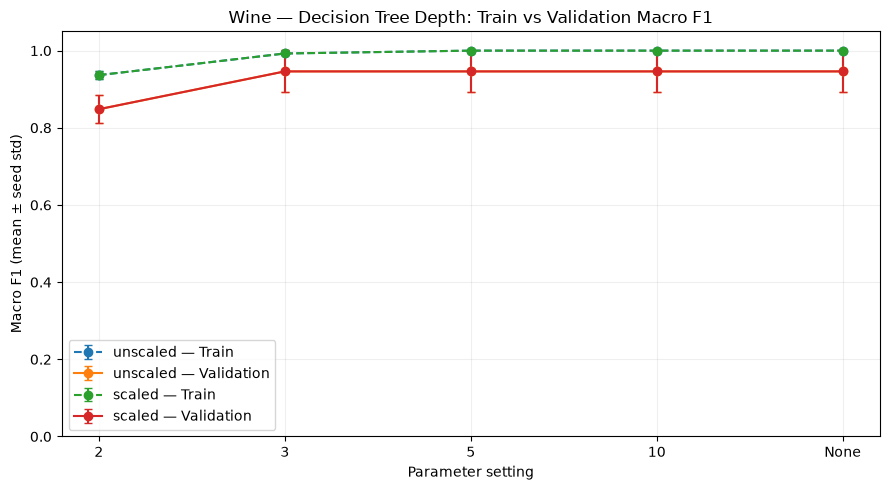

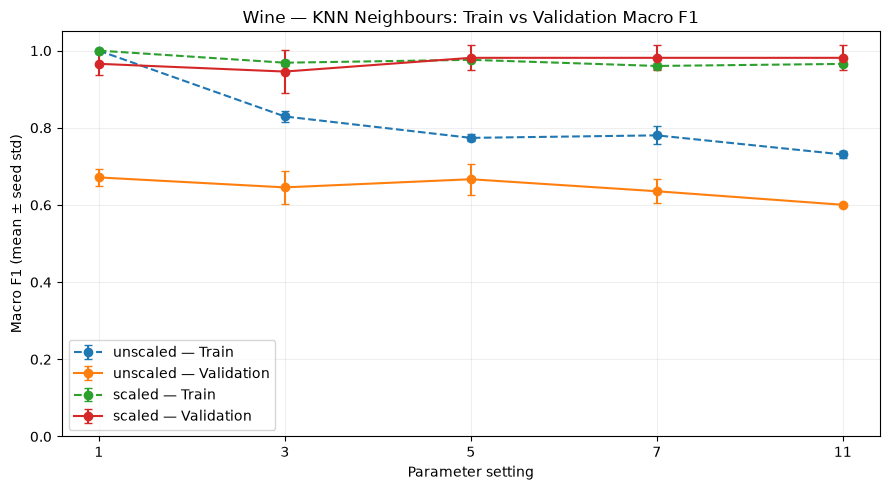

In [10]:
def plot_parameter_comparison(algorithm, ordered_models, x_labels, filename, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    xpos = np.arange(len(ordered_models))
    for representation in ["unscaled", "scaled"]:
        subset = wine_classifier_summary.loc[
            (wine_classifier_summary["algorithm"] == algorithm) &
            (wine_classifier_summary["representation"] == representation)
        ].set_index("model").reindex(ordered_models)
        assert subset["f1_macro_mean"].notna().all()
        for stage, mean_col, std_col, style in [
            ("Train", "train_macro_f1_mean", "train_macro_f1_std", "--"),
            ("Validation", "f1_macro_mean", "f1_macro_std", "-"),
        ]:
            ax.errorbar(xpos, subset[mean_col], yerr=subset[std_col],
                        marker="o", linestyle=style, capsize=3,
                        label=f"{representation} — {stage}")
    ax.set_xticks(xpos, x_labels)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Parameter setting")
    ax.set_ylabel("Macro F1 (mean ± seed std)")
    ax.set_title(title)
    ax.grid(alpha=0.2)
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()

plot_parameter_comparison(
    "DecisionTree", [f"DecisionTree_depth_{d}" for d in [2, 3, 5, 10, None]],
    ["2", "3", "5", "10", "None"], "wine_tree_depth_comparison.png",
    "Wine — Decision Tree Depth: Train vs Validation Macro F1"
)
plot_parameter_comparison(
    "KNN", [f"KNN_k_{k}" for k in [1, 3, 5, 7, 11]],
    ["1", "3", "5", "7", "11"], "wine_knn_neighbours_comparison.png",
    "Wine — KNN Neighbours: Train vs Validation Macro F1"
)

## 9. Final Test Evaluation of the Selected Classifier

Use the **already fitted seed-42 model** corresponding to the selected validation configuration. No retraining and no test-based model choice.

In [11]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, auc)

final_model = wine_seed42_models[best_config_id]
final_representation = best["representation"]
X_test_final = fixed_test_features(final_representation)
final_pred = final_model.predict(X_test_final)
assert list(final_model.classes_) == LABELS
final_proba = final_model.predict_proba(X_test_final)

wine_test_metrics = {
    "accuracy": accuracy_score(y_test, final_pred),
    "precision_macro": precision_score(y_test, final_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, final_pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, final_pred, average="macro", zero_division=0),
    "roc_auc": roc_auc_score(y_test, final_proba, labels=LABELS,
                             multi_class="ovr", average="macro"),
}
wine_classifier_test = pd.DataFrame([{
    "dataset": DATASET,
    "selected_config": best_config_id,
    "model": best["model"],
    "representation": final_representation,
    "evaluation_seed": 42,
    "validation_f1_mean": best["f1_macro_mean"],
    "validation_f1_std": best["f1_macro_std"],
    **wine_test_metrics,
}])
notebook_display(wine_classifier_test)
print("Per-class classification report:")
print(classification_report(y_test, final_pred, labels=LABELS,
                            target_names=list(wine.target_names), zero_division=0))
print("Difference: test macro F1 minus validation mean macro F1 =",
      wine_test_metrics["f1_macro"] - best["f1_macro_mean"])

,dataset,selected_config,model,representation,evaluation_seed,validation_f1_mean,validation_f1_std,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,Wine,wine_knn_k_11_scaled,KNN_k_11,scaled,42,0.981352,0.032299,1.0,1.0,1.0,1.0,1.0


Per-class classification report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Difference: test macro F1 minus validation mean macro F1 = 0.01864801864801857


Confusion matrix (rows=Actual, columns=Predicted):
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]


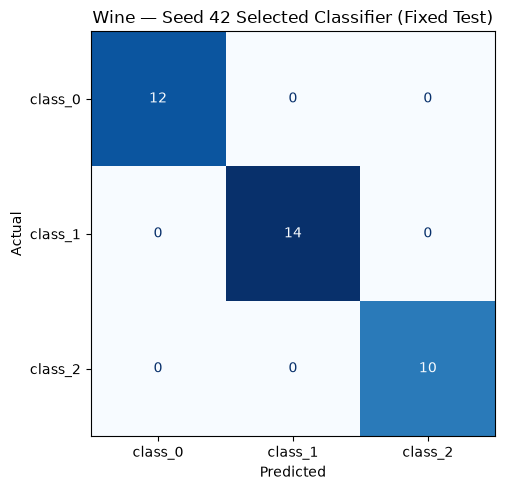

No test misclassifications. This does NOT prove perfect generalisation.
Manual class 0 (class_0) check:
TP, FP, FN: 12 0 0
Precision, recall, F1: 1.0 1.0 1.0
Corresponding classification report row: {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 12.0}
No misclassified test rows to report.
Limitation: one fixed test split; validation subsets are small and repeated splits overlap.


In [12]:
cm = confusion_matrix(y_test, final_pred, labels=LABELS)
print("Confusion matrix (rows=Actual, columns=Predicted):")
print(cm)
cm_figure, cm_ax = plt.subplots(figsize=(6, 5))
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)
cm_display.plot(ax=cm_ax, cmap="Blues", values_format="d", colorbar=False)
cm_ax.set_title("Wine — Seed 42 Selected Classifier (Fixed Test)")
cm_ax.set_xlabel("Predicted")
cm_ax.set_ylabel("Actual")
cm_figure.tight_layout()
cm_figure.savefig(FIG_DIR / "wine_classifier_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# Identify the largest off-diagonal error, if any.
errors_only = cm.copy()
np.fill_diagonal(errors_only, 0)
if errors_only.sum() == 0:
    print("No test misclassifications. This does NOT prove perfect generalisation.")
else:
    max_pos = np.unravel_index(np.argmax(errors_only), errors_only.shape)
    print("Largest off-diagonal confusion:",
          f"actual class {LABELS[max_pos[0]]} -> predicted class {LABELS[max_pos[1]]}",
          "count:", errors_only[max_pos])

# Manually verify one class's precision, recall, F1 against its per-class report.
manual_class = LABELS[int(np.argmax(cm.sum(axis=1) - np.diag(cm)))]
class_i = LABELS.index(manual_class)
tp = int(cm[class_i, class_i])
fp = int(cm[:, class_i].sum() - tp)
fn = int(cm[class_i, :].sum() - tp)
precision_manual = tp / (tp + fp) if tp + fp else float("nan")
recall_manual = tp / (tp + fn) if tp + fn else float("nan")
f1_manual = (2 * precision_manual * recall_manual / (precision_manual + recall_manual)
             if (precision_manual + recall_manual) > 0 else float("nan"))
print(f"Manual class {manual_class} ({wine.target_names[class_i]}) check:")
print("TP, FP, FN:", tp, fp, fn)
print("Precision, recall, F1:", precision_manual, recall_manual, f1_manual)
report_values = classification_report(y_test, final_pred, labels=LABELS,
                                       target_names=list(wine.target_names),
                                       zero_division=0, output_dict=True)
print("Corresponding classification report row:", report_values[wine.target_names[class_i]])

misclassified = np.flatnonzero(y_test.to_numpy() != final_pred)
if len(misclassified):
    pos = int(misclassified[0])
    original_index = y_test.index[pos]
    print("One actual misclassification:",
          f"row index={original_index}, true={y_test.iloc[pos]}, predicted={final_pred[pos]}")
    print("Its original features (first 5):", X_df.loc[original_index].head().to_dict())
else:
    print("No misclassified test rows to report.")
print("Limitation: one fixed test split; validation subsets are small and repeated splits overlap.")

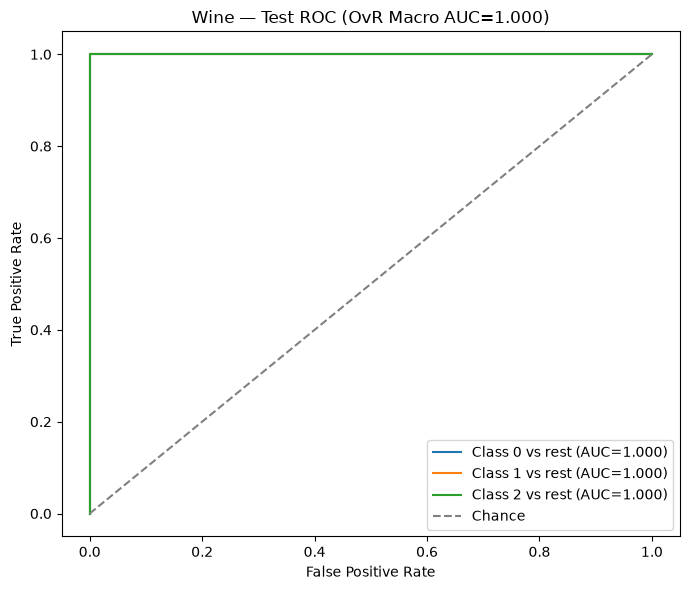

Changing a probability threshold trades false positives against false negatives;
do NOT tune a new threshold on this final test set.


In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
for class_i, class_label in enumerate(LABELS):
    y_binary = (y_test.to_numpy() == class_label).astype(int)
    fpr, tpr, _ = roc_curve(y_binary, final_proba[:, class_i])
    class_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr,
            label=f"Class {class_label} vs rest (AUC={class_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
       title=f"Wine — Test ROC (OvR Macro AUC={wine_test_metrics['roc_auc']:.3f})")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "wine_classifier_roc_ovr.png", dpi=200, bbox_inches="tight")
plt.show()
print("Changing a probability threshold trades false positives against false negatives;")
print("do NOT tune a new threshold on this final test set.")

## 10. K-Means Clustering

Three seeds × two representations = **six K-Means fits** for Wine with three clusters, `n_init=10`. Fit with feature data only. Report train inertia, validation ARI/silhouette, and seed-42 test comparisons for both representations.

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

def safe_silhouette(features, cluster_labels):
    count = len(np.unique(cluster_labels))
    if not (1 < count < len(cluster_labels)):
        return float("nan")
    return silhouette_score(features, cluster_labels)

wine_kmeans_records = []
wine_kmeans_models = {}
for seed in SEEDS:
    for representation in ["unscaled", "scaled"]:
        X_tr, X_val = training_validation_features(seed, representation)
        model = KMeans(n_clusters=3, random_state=seed, n_init=10)
        model.fit(X_tr)  # IMPORTANT: no y_train supplied
        val_clusters = model.predict(X_val)
        wine_kmeans_records.append({
            "dataset": DATASET,
            "run_id": f"wine_kmeans_{representation}_s{seed}",
            "seed": seed,
            "representation": representation,
            "inertia": model.inertia_,  # TRAIN inertia, not test or validation
            "ari": adjusted_rand_score(splits[seed]["y_val"], val_clusters),
            "silhouette": safe_silhouette(X_val, val_clusters),
        })
        wine_kmeans_models[(seed, representation)] = model

wine_kmeans_runs = pd.DataFrame(wine_kmeans_records)
assert len(wine_kmeans_runs) == 6
notebook_display(wine_kmeans_runs)

wine_kmeans_summary = wine_kmeans_runs.groupby(
    ["dataset", "representation"], as_index=False
).agg(
    inertia_mean=("inertia", "mean"),
    inertia_std=("inertia", "std"),
    ari_mean=("ari", "mean"),
    ari_std=("ari", "std"),
    silhouette_mean=("silhouette", "mean"),
    silhouette_std=("silhouette", "std"),
    silhouette_valid_seeds=("silhouette", "count"),
)
notebook_display(wine_kmeans_summary)
print("Never directly compare raw scaled vs unscaled inertia values.")

,dataset,run_id,seed,representation,inertia,ari,silhouette
0,Wine,wine_kmeans_unscaled_s42,42,unscaled,1.350496e+06,0.282836,0.486994
1,Wine,wine_kmeans_scaled_s42,42,scaled,8.747391e+02,1.000000,0.251637
2,Wine,wine_kmeans_unscaled_s52,52,unscaled,1.303675e+06,0.400588,0.555887
3,Wine,wine_kmeans_scaled_s52,52,scaled,8.904355e+02,1.000000,0.301008
4,Wine,wine_kmeans_unscaled_s62,62,unscaled,1.390754e+06,0.400588,0.686671
5,Wine,wine_kmeans_scaled_s62,62,scaled,8.722466e+02,1.000000,0.272587


,dataset,representation,inertia_mean,inertia_std,ari_mean,ari_std,silhouette_mean,silhouette_std,silhouette_valid_seeds
0,Wine,scaled,8.791404e+02,9.860948,1.000000,0.000000,0.275077,0.024780,3
1,Wine,unscaled,1.348308e+06,43580.909759,0.361337,0.067984,0.576517,0.101425,3


Never directly compare raw scaled vs unscaled inertia values.


In [15]:
wine_kmeans_test_records = []
wine_contingencies = {}
for representation in ["unscaled", "scaled"]:
    model = wine_kmeans_models[(42, representation)]
    X_test_rep = fixed_test_features(representation)
    cluster_ids = model.predict(X_test_rep)
    cluster_count_series = pd.Series(cluster_ids).value_counts().sort_index()
    cluster_counts_string = "; ".join(
        f"{int(cid)}:{int(count)}" for cid, count in cluster_count_series.items()
    )
    wine_kmeans_test_records.append({
        "dataset": DATASET,
        "seed": 42,
        "representation": representation,
        "cluster_counts": cluster_counts_string,
        "ari": adjusted_rand_score(y_test, cluster_ids),
        "silhouette": safe_silhouette(X_test_rep, cluster_ids),
    })
    contingency = pd.crosstab(
        pd.Series(y_test.to_numpy(), index=X_test.index, name="True Class"),
        pd.Series(cluster_ids, index=X_test.index, name="Predicted Cluster")
    )
    wine_contingencies[representation] = contingency
    print(f"\n{representation.upper()} — test cluster counts: {cluster_counts_string}")
    notebook_display(contingency)

wine_kmeans_test = pd.DataFrame(wine_kmeans_test_records)
notebook_display(wine_kmeans_test)


UNSCALED — test cluster counts: 0:14; 1:10; 2:12


Predicted Cluster,0,1,2
True Class,,,
0,2,10,0
1,5,0,9
2,7,0,3



SCALED — test cluster counts: 0:13; 1:13; 2:10


Predicted Cluster,0,1,2
True Class,,,
0,12,0,0
1,1,13,0
2,0,0,10


,dataset,seed,representation,cluster_counts,ari,silhouette
0,Wine,42,unscaled,0:14; 1:10; 2:12,0.373323,0.49288
1,Wine,42,scaled,0:13; 1:13; 2:10,0.908794,0.27112


Two original visualization features: ['alcohol', 'color_intensity']
Ranges on seed-42 training data:


,alcohol,color_intensity
min,11.030000,1.280000
max,14.830000,11.750000
std,0.790561,2.274017


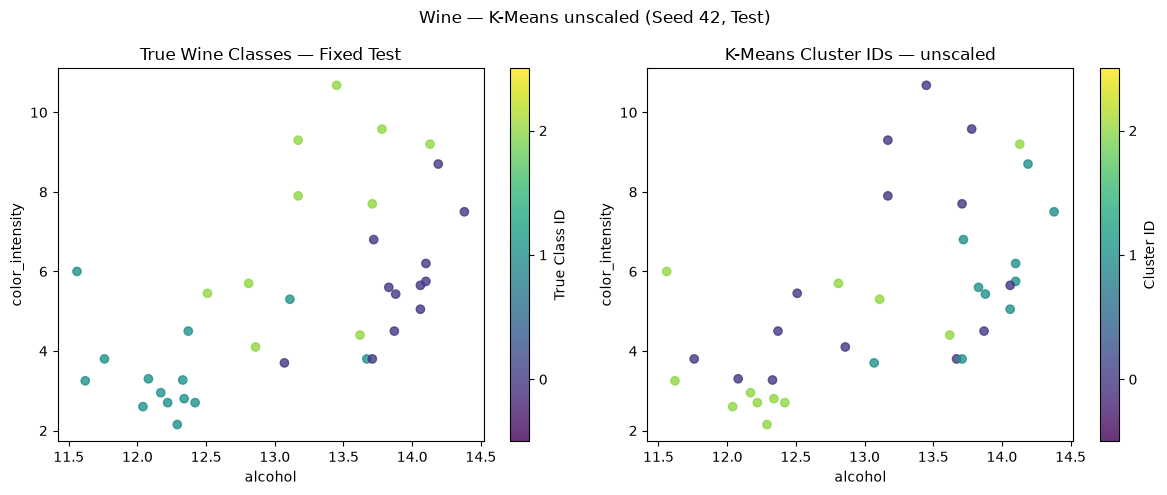

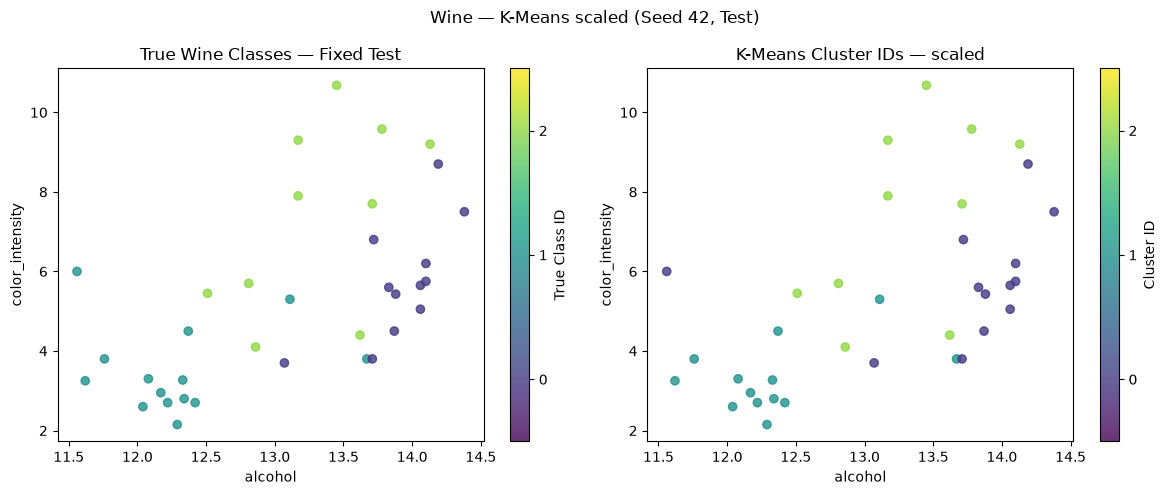

Clusters were fitted using all 13 features; the figures show two-feature projections.


In [16]:
# Plot choices fixed using seed-42 TRAINING data, not final test labels.
# These two original measured features are used for a readable 2D projection only.
plot_features = ["alcohol", "color_intensity"]
print("Two original visualization features:", plot_features)
print("Ranges on seed-42 training data:")
notebook_display(splits[42]["X_train"][plot_features].agg(["min", "max", "std"]))

for representation in ["unscaled", "scaled"]:
    model = wine_kmeans_models[(42, representation)]
    cluster_ids = model.predict(fixed_test_features(representation))
    x = X_test[plot_features[0]].to_numpy()
    y_axis = X_test[plot_features[1]].to_numpy()
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    actual_scatter = axes[0].scatter(x, y_axis, c=y_test.to_numpy(), cmap="viridis",
                                     vmin=-0.5, vmax=2.5, alpha=0.8)
    axes[0].set_title("True Wine Classes — Fixed Test")
    fig.colorbar(actual_scatter, ax=axes[0], ticks=LABELS, label="True Class ID")
    cluster_scatter = axes[1].scatter(x, y_axis, c=cluster_ids, cmap="viridis",
                                      vmin=-0.5, vmax=2.5, alpha=0.8)
    axes[1].set_title(f"K-Means Cluster IDs — {representation}")
    fig.colorbar(cluster_scatter, ax=axes[1], ticks=LABELS, label="Cluster ID")
    for ax in axes:
        ax.set_xlabel(plot_features[0])
        ax.set_ylabel(plot_features[1])
    fig.suptitle(f"Wine — K-Means {representation} (Seed 42, Test)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"wine_kmeans_{representation}_test.png", dpi=200,
                bbox_inches="tight")
    plt.show()
print("Clusters were fitted using all 13 features; the figures show two-feature projections.")

## 11. Comparing the Two Datasets

The combined cross-dataset tables are generated **after export in Section 12**. Write the final explanations yourself: best classifier vs representation; scaling effects; tree-depth/k-neighbour patterns; seed variability; confusion-matrix errors; K-Means ARI vs class mixing; one future-work idea. Keep validation and test claims separate.

## 12. Required CSV Exports and Run Inventory

The project needs **six combined CSVs**, with both datasets: 132 classifier runs, 44 classifier summary rows, 2 classifier tests, 12 K-Means runs, 4 K-Means summary rows, 4 K-Means tests.

This export reads existing Breast Cancer CSVs from the project folder, enriches old columns where possible, merges Wine rows, and makes `.before_wine_backup.csv` copies before replacing existing files. Rerunning does not duplicate Wine rows.

In [17]:
from shutil import copy2

# Existing Breast Cancer CSVs must be in this notebook's working directory.
CSV_FILENAMES = ["classifier_runs.csv", "classifier_summary.csv", "classifier_test.csv",
                 "kmeans_runs.csv", "kmeans_summary.csv", "kmeans_test.csv"]
for filename in CSV_FILENAMES:
    if not Path(filename).is_file():
        raise FileNotFoundError(
            f"Missing {filename}. Copy the Breast Cancer CSV into this project folder first. "
            "No files have been overwritten."
        )

# Preserve an original snapshot for recovery (written once).
for filename in CSV_FILENAMES:
    backup = Path(filename.replace(".csv", ".before_wine_backup.csv"))
    if not backup.exists():
        copy2(filename, backup)
print("Created/preserved backups before merging.")

# Load only Breast Cancer records from current CSVs; ignore any previously exported Wine
# records so this cell is safe to rerun without multiplying rows.
def breast_only(filename):
    frame = pd.read_csv(filename)
    if "dataset" not in frame.columns:
        frame["dataset"] = "Breast Cancer"
    return frame.loc[frame["dataset"].eq("Breast Cancer")].copy()

bc_classifier_runs = breast_only("classifier_runs.csv")
bc_classifier_test = breast_only("classifier_test.csv")
bc_kmeans_runs = breast_only("kmeans_runs.csv")
bc_kmeans_test = breast_only("kmeans_test.csv")

# Original Breast Cancer classifier runs may have legacy columns (seed, representation,
# model and performance metrics) but no run/config IDs. Restore those fields from names.
def classifier_metadata(row):
    m = str(row["model"])
    if m.startswith("DecisionTree_depth_"):
        p = m.replace("DecisionTree_depth_", "")
        return "DecisionTree", f"max_depth={p}", f"dt_depth_{p}"
    if m.startswith("KNN_k_"):
        p = m.replace("KNN_k_", "")
        return "KNN", f"n_neighbors={p}; weights=uniform; metric=euclidean", f"knn_k_{p}"
    if m == "GaussianNB":
        return "GaussianNB", "defaults", "gaussiannb_default"
    raise ValueError(f"Unknown Breast Cancer model name: {m}")

for idx, row in bc_classifier_runs.iterrows():
    algorithm, parameter, slug = classifier_metadata(row)
    config = f"breast_cancer_{slug}_{row['representation']}"
    bc_classifier_runs.loc[idx, "algorithm"] = algorithm
    bc_classifier_runs.loc[idx, "parameter"] = parameter
    bc_classifier_runs.loc[idx, "config_id"] = config
    bc_classifier_runs.loc[idx, "run_id"] = f"{config}_s{int(row['seed'])}"

all_classifier_runs = pd.concat([bc_classifier_runs, wine_classifier_runs], ignore_index=True)
all_classifier_summary = pd.concat([
    summarize_classifier_runs(bc_classifier_runs),
    summarize_classifier_runs(wine_classifier_runs),
], ignore_index=True)
all_classifier_summary = all_classifier_summary.sort_values(
    ["dataset", "f1_macro_mean"], ascending=[True, False]
).reset_index(drop=True)

# Add the predeclared seed-42 selection metadata to any older BC final-test file.
bc_best = ranked_configurations(
    all_classifier_summary.loc[all_classifier_summary["dataset"].eq("Breast Cancer")]
).iloc[0]
for idx in bc_classifier_test.index:
    bc_classifier_test.loc[idx, "selected_config"] = bc_best["config_id"]
    bc_classifier_test.loc[idx, "evaluation_seed"] = 42
    bc_classifier_test.loc[idx, "validation_f1_mean"] = bc_best["f1_macro_mean"]
    bc_classifier_test.loc[idx, "validation_f1_std"] = bc_best["f1_macro_std"]
all_classifier_test = pd.concat([bc_classifier_test, wine_classifier_test], ignore_index=True)

# K-Means runs: add reproducible IDs if older BC file did not contain them.
for idx, row in bc_kmeans_runs.iterrows():
    bc_kmeans_runs.loc[idx, "run_id"] = (
        f"breast_cancer_kmeans_{row['representation']}_s{int(row['seed'])}"
    )
all_kmeans_runs = pd.concat([bc_kmeans_runs, wine_kmeans_runs], ignore_index=True)
all_kmeans_summary = all_kmeans_runs.groupby(
    ["dataset", "representation"], as_index=False
).agg(
    inertia_mean=("inertia", "mean"), inertia_std=("inertia", "std"),
    ari_mean=("ari", "mean"), ari_std=("ari", "std"),
    silhouette_mean=("silhouette", "mean"),
    silhouette_std=("silhouette", "std"),
    silhouette_valid_seeds=("silhouette", "count"),
)

# Previously observed, verified BC contingency counts are included as fallback ONLY when
# the old BC CSV did not save cluster counts (no new model fitting; these came from the
# already displayed BC test contingency tables). Recheck if the BC notebook is changed.
BC_VERIFIED_CLUSTER_COUNTS = {"unscaled": "0:86; 1:28", "scaled": "0:74; 1:40"}
if "cluster_counts" not in bc_kmeans_test:
    bc_kmeans_test["cluster_counts"] = pd.NA
for idx, row in bc_kmeans_test.iterrows():
    if pd.isna(row["cluster_counts"]) or not str(row["cluster_counts"]).strip():
        bc_kmeans_test.loc[idx, "cluster_counts"] = BC_VERIFIED_CLUSTER_COUNTS[str(row["representation"])]
all_kmeans_test = pd.concat([bc_kmeans_test, wine_kmeans_test], ignore_index=True)

csv_outputs = {
    "classifier_runs.csv": all_classifier_runs,
    "classifier_summary.csv": all_classifier_summary,
    "classifier_test.csv": all_classifier_test,
    "kmeans_runs.csv": all_kmeans_runs,
    "kmeans_summary.csv": all_kmeans_summary,
    "kmeans_test.csv": all_kmeans_test,
}
expected_rows = {
    "classifier_runs.csv": 132, "classifier_summary.csv": 44,
    "classifier_test.csv": 2, "kmeans_runs.csv": 12,
    "kmeans_summary.csv": 4, "kmeans_test.csv": 4,
}
for filename, frame in csv_outputs.items():
    if len(frame) != expected_rows[filename]:
        raise ValueError(
            f"{filename}: expected {expected_rows[filename]} rows, found {len(frame)}. "
            "Existing CSVs left unchanged; inspect Breast Cancer CSVs."
        )
assert all_classifier_runs["run_id"].is_unique
assert all_kmeans_runs["run_id"].is_unique

for filename, frame in csv_outputs.items():
    frame.to_csv(filename, index=False)
    print(f"Saved {filename}: {len(frame)} rows")
print("Combined CSV exports are complete.")

Created/preserved backups before merging.
Saved classifier_runs.csv: 132 rows
Saved classifier_summary.csv: 44 rows
Saved classifier_test.csv: 2 rows
Saved kmeans_runs.csv: 12 rows
Saved kmeans_summary.csv: 4 rows
Saved kmeans_test.csv: 4 rows
Combined CSV exports are complete.


In [18]:
print("\nSelected classifier configurations (each from validation data):")
winners = []
for dataset, subset in all_classifier_summary.groupby("dataset"):
    winner = ranked_configurations(subset).iloc[0]
    winners.append({
        "dataset": dataset,
        "config": winner["config_id"],
        "representation": winner["representation"],
        "mean_val_macro_f1": winner["f1_macro_mean"],
        "std_val_macro_f1": winner["f1_macro_std"],
    })
notebook_display(pd.DataFrame(winners))
print("\nBoth datasets' classifier test results:")
notebook_display(all_classifier_test)
print("\nBoth datasets' K-Means test results:")
notebook_display(all_kmeans_test)
print("\nKNN scaling example by dataset (k=7, validation mean F1):")
notebook_display(all_classifier_summary.loc[
    all_classifier_summary["model"].eq("KNN_k_7"),
    ["dataset", "representation", "f1_macro_mean", "f1_macro_std"]
].sort_values(["dataset", "representation"]))
print("\nK-Means validation comparison:")
notebook_display(all_kmeans_summary[["dataset", "representation", "ari_mean", "ari_std",
                                     "silhouette_mean", "silhouette_std"]])

figure_files = list(FIG_DIR.glob("*.png"))
print(f"\nPNG files in {FIG_DIR}: {len(figure_files)}")
if len(figure_files) < 18:
    print("Reminder: assignment requires at least 18 figures across BOTH datasets.")
print("Before submitting: document interpretations, verify original BC notebook plots saved, and run both notebooks fresh.")


Selected classifier configurations (each from validation data):


,dataset,config,representation,mean_val_macro_f1,std_val_macro_f1
0,Breast Cancer,breast_cancer_knn_k_7_scaled,scaled,0.967675,0.029718
1,Wine,wine_knn_k_11_scaled,scaled,0.981352,0.032299



Both datasets' classifier test results:


,dataset,model,representation,accuracy,precision_macro,recall_macro,f1_macro,roc_auc,selected_config,evaluation_seed,validation_f1_mean,validation_f1_std
0,Breast Cancer,KNN_k_7,scaled,0.973684,0.98,0.964286,0.971277,0.988757,breast_cancer_knn_k_7_scaled,42.0,0.967675,0.029718
1,Wine,KNN_k_11,scaled,1.000000,1.00,1.000000,1.000000,1.000000,wine_knn_k_11_scaled,42.0,0.981352,0.032299



Both datasets' K-Means test results:


,dataset,seed,representation,ari,silhouette,cluster_counts
0,Breast Cancer,42,unscaled,0.558488,0.711999,0:86; 1:28
1,Breast Cancer,42,scaled,0.735381,0.325062,0:74; 1:40
2,Wine,42,unscaled,0.373323,0.492880,0:14; 1:10; 2:12
3,Wine,42,scaled,0.908794,0.271120,0:13; 1:13; 2:10



KNN scaling example by dataset (k=7, validation mean F1):


,dataset,representation,f1_macro_mean,f1_macro_std
0,Breast Cancer,scaled,0.967675,0.029718
19,Breast Cancer,unscaled,0.904040,0.001278
24,Wine,scaled,0.981352,0.032299
42,Wine,unscaled,0.635589,0.031621



K-Means validation comparison:


,dataset,representation,ari_mean,ari_std,silhouette_mean,silhouette_std
0,Breast Cancer,scaled,0.581255,0.142378,0.312086,0.054725
1,Breast Cancer,unscaled,0.504349,0.106423,0.677325,0.033440
2,Wine,scaled,1.000000,0.000000,0.275077,0.024780
3,Wine,unscaled,0.361337,0.067984,0.576517,0.101425



PNG files in figures: 21
Before submitting: document interpretations, verify original BC notebook plots saved, and run both notebooks fresh.
